Today's topics:

* linear interpolation with `np.interp`
* resampling data onto an even grid
* interpolation and extrapolation
* checking a figure against its numbers
* a figure caption with the data source and AI use
* AI agents: a model, tools, and a feedback loop

# Crushing a printed lattice

Today we will finish the lattice exercise and see what an AI agent is.

<img src="https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/digitizing_chart.png" alt="Stress-strain curve of a printed lattice in compression, stress in MPa from 0 to 80 against strain from 0 to 0.8, drawn as a blue dashed line. The stress rises to a peak of about 45 MPa near strain 0.08, drops to about 4 MPa near 0.13, then wavers between about 10 and 20 MPa out to strain 0.65. Inset video frames show elastic deformation, shear band deformation, deformation, and the start of densification." width=540/>

*Figure 3 of Al-Saedi and Masood, "Mechanical performance of functionally graded lattice structures made with selective laser melting 3D printing," IOP Conf. Ser.: Mater. Sci. Eng. 433, 012078 (2018), [doi:10.1088/1757-899X/433/1/012078](https://doi.org/10.1088/1757-899X/433/1/012078), [CC BY 3.0](https://creativecommons.org/licenses/by/3.0/).*

Last time we asked an AI assistant in AI Studio to extract this curve as numbers.
Then we checked the extraction against the figure.

The energy absorbed per unit volume is the area under the stress-strain curve.
How much energy does this lattice absorb before it densifies, near a strain of 0.6?

## Reloading the data

1. Open your saved AI Studio chat from last time.
2. Copy only the CSV rows of your checked extraction and paste them between the triple quotes below.
3. Set `LIVE_MODE = True` and run the cell.

If you have no usable extraction, leave `LIVE_MODE = False`.
Then `extraction` is the reference file, made with WebPlotDigitizer (Appendix A).
If Colab falls back to the reference, upload that reference CSV to AI Studio and tell the assistant to use it instead.

If your chat is lost, open a new chat with a model that can run code.
Upload your saved CSV, or the reference from [this link](https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/digitizing_chart_wpd.csv), and paste:

```
I uploaded a CSV of the compressive stress-strain curve of a 3D-printed metal lattice.
It has no header row. The columns are strain and stress in MPa.
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO  # reads a CSV from text

url = 'https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/digitizing_chart_wpd.csv'
reference = pd.read_csv(url, header=None, names=['strain', 'stress_MPa'])  # no header row

In [2]:
LIVE_MODE = False  # True: use your own extraction from AI Studio

pasted_extraction = """
"""

extraction = reference  # the default, so the notebook runs from top to bottom

if LIVE_MODE:
    if pasted_extraction.strip() == '':
        print('The paste is empty. Using the reference.')
    else:
        try:
            pasted = pd.read_csv(StringIO(pasted_extraction), header=None)
        except (pd.errors.ParserError, pd.errors.EmptyDataError):  # rows with different numbers of fields
            print('Could not read the paste. Copy only the CSV rows, two numbers per row. Using the reference.')
            pasted = None
        if pasted is None:
            pass
        elif pasted.shape[1] != 2:
            print('columns pasted:', pasted.shape[1])
            print('Expected 2 columns. Using the reference.')
        else:
            pasted.columns = ['strain', 'stress_MPa']
            rows_before = len(pasted)
            # a header row or stray text becomes NaN, and dropna removes it
            pasted['strain'] = pd.to_numeric(pasted['strain'], errors='coerce')
            pasted['stress_MPa'] = pd.to_numeric(pasted['stress_MPa'], errors='coerce')
            pasted = pasted.dropna()
            print('rows removed:', rows_before - len(pasted))
            repeats = pasted['strain'].duplicated().sum()  # True counts as 1
            print('repeated strains:', repeats)
            if len(pasted) == 0 or repeats > 0:
                print('Empty table or repeated strains. Using the reference.')
            else:
                extraction = pasted

if extraction is reference:
    print('Comparing the reference with itself.')

# the sort prepares extraction for the later comparison with np.interp
extraction = extraction.sort_values('strain')

Comparing the reference with itself.


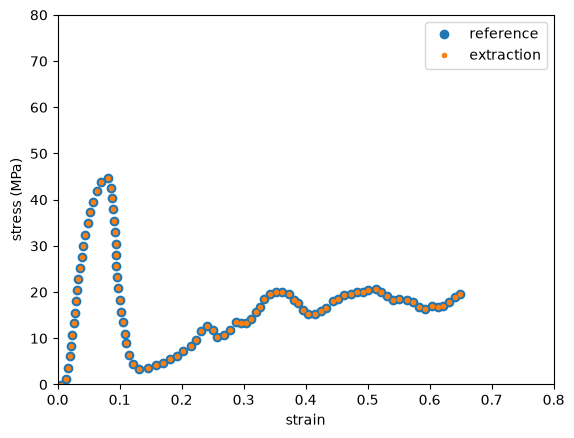

In [3]:
strain = reference['strain']
stress = reference['stress_MPa']

fig, ax = plt.subplots()
ax.plot(strain, stress, 'o', label='reference')
ax.plot(extraction['strain'], extraction['stress_MPa'], '.', label='extraction')
ax.set_xlim(0, 0.8)  # the same limits as the figure
ax.set_ylim(0, 80)
ax.set_xlabel('strain')
ax.set_ylabel('stress (MPa)')
ax.legend()

In [4]:
print(len(reference), len(extraction))  # number of points
print(extraction.min())  # smallest strain and stress
print(extraction.max())  # largest strain and stress

93 93
strain        0.005130
stress_MPa   -0.027811
dtype: float64
strain         0.648461
stress_MPa    44.745804
dtype: float64


The reference has 93 points, from a strain of 0.005 to 0.648, with a peak of 44.7 MPa.
If your extraction was accepted, your count should equal the number of points the assistant reported.

# Energy under the curve

## Step 3: ask for the energy

Paste this request in the same AI Studio chat:

```
Run the calculation on exactly the CSV rows you returned, or the uploaded replacement CSV. Sort by strain first.
Report the row count and strain range; do not silently remove or replace points.
Compute the energy absorbed per unit volume up to a strain of 0.6, in MJ/m^3.
Stress in MPa times strain gives MJ/m^3.
Do it two ways, run the code, and show it. Call both results energy estimates:
(a) the mean stress of the points with strain up to 0.6, times 0.6
(b) the stress from numpy's np.interp at 61 evenly spaced strains from 0 to 0.6, then the mean of those, times 0.6

Then make a publication-quality figure of stress against strain from the same points, and show it.
```

While it runs, let's do the same calculation here.

## A first estimate

The area under a curve is its average height times its width.

Let's average the reference stress of every point up to a strain of 0.6:

In [5]:
before_dense = strain <= 0.6
print(np.mean(stress[before_dense]) * 0.6)  # MJ/m^3

11.012309812361117


About 11 MJ/m$^3$.

But look at the reference points on the plot.
They are concentrated on the steep rise and drop around the peak.
How many sit below a strain of 0.1?

In [6]:
print(np.sum(strain < 0.1))  # True counts as 1

31


A third of the points sit near the peak, where the stress is highest.
In a plain mean, the peak region gets too much weight.

We want the stress at evenly spaced strains instead.
Most of those strains fall between our points.

# Interpolation

## Between two points

What is the stress at a strain of 0.253?
Here are the reference points around it:

In [7]:
display(reference[(strain > 0.24) & (strain < 0.27)])

,strain,stress_MPa
48,0.241038,12.755100
49,0.250326,11.752414
50,0.257756,10.334012
51,0.268902,10.720074


**Linear interpolation** estimates the value from a straight line between the two neighbors.

`np.interp(x_new, x, y)` does this for us.
The known `x` values must be in increasing order.

In [8]:
print(np.interp(0.253, strain, stress))  # MPa

11.241995109018898


11.24 MPa sits between the stresses of its two neighbors, as it should.

## On an even grid

`np.interp` also takes an array of new `x` values.

Let's make 61 evenly spaced strains from 0 to 0.6 and interpolate the stress at each:

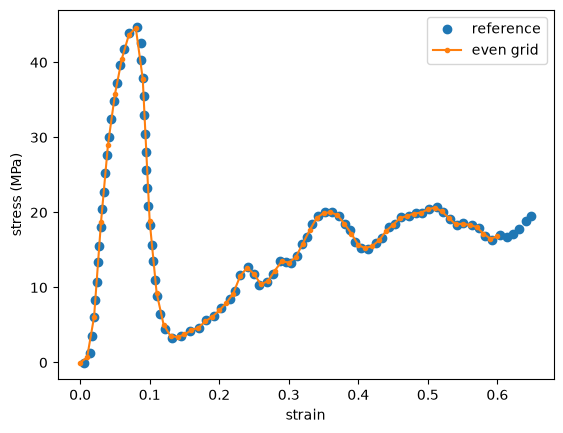

In [9]:
strain_grid = np.linspace(0, 0.6, 61)  # steps of 0.01
stress_grid = np.interp(strain_grid, strain, stress)

fig, ax = plt.subplots()
ax.plot(strain, stress, 'o', label='reference')
ax.plot(strain_grid, stress_grid, '.-', label='even grid')
ax.set_xlabel('strain')
ax.set_ylabel('stress (MPa)')
ax.legend()

Now every strain counts equally.
Let's repeat the energy estimate with the grid:

In [10]:
print(np.mean(stress_grid) * 0.6)  # MJ/m^3

9.684245450710163


About 9.7 MJ/m$^3$, 12% less than the plain mean.

Now the same grid and the same formula on your extraction.
First check the largest strain of your extraction, printed earlier.
If it ends before 0.6, the grid energy uses its last stress for every strain after that.
Correct it, or use the reference.
The reference starts slightly above zero strain, so its grid pads the first short interval the same way.

In [11]:
extraction_grid = np.interp(strain_grid, extraction['strain'], extraction['stress_MPa'])
print(np.mean(extraction_grid) * 0.6)  # MJ/m^3

9.684245450710163


With `LIVE_MODE = False` this repeats the reference, 9.7 MJ/m$^3$.

Compare this number with answer (b) from AI Studio.
Same points, same grid, and same formula should give the same number.
If they differ, first check that you pasted every row.
Then read the assistant's code for the step that differs.

If your extraction's points are evenly spaced in strain, its answers (a) and (b) are close.
Its points are not concentrated near the peak.

So up to a strain of 0.6, this lattice absorbs about 10 MJ per cubic meter: 9.7 from the reference.

### [Check your understanding]

The **plateau stress** is the average stress while the cells crush, here between strains 0.2 and 0.6.

1. Compute it from the reference points between 0.2 and 0.6.
   The mask `plateau` below selects them.
2. Compute it again from 41 evenly spaced strains between 0.2 and 0.6, using `np.interp`.
3. Repeat step 2 on `extraction`.

How different are the first two?
Why did the grid change the energy estimate but not this one?

In [12]:
plateau = (strain >= 0.2) & (strain <= 0.6)

# Outside the data

The reference stops at a strain of 0.648.
What does `np.interp` give at 0.7?

In [13]:
print(np.interp(0.7, strain, stress))
print(stress.iloc[-1])  # the last reference point

19.528383165937136
19.528383165937136


Outside the data, `np.interp` returns the value at the nearest end.
It gives no error and no warning.

But at 0.7 the lattice is densifying.
Its stress climbs as the struts pack together.
The real stress is likely higher than 19.5 MPa, and we have no points there to check.

Estimating between our points is **interpolation**.
Beyond the last point it is **extrapolation**.

# A figure for a report

## Checking the assistant's figure

Look at the figure from Step 3 and check it against the numbers, not against how it looks:

* **Units.** Each axis names its quantity and units: strain has none, stress is in MPa.
* **Scale.** The stress spans about 0 to 45 MPa, so a linear axis works.
* **Limits.** Compare the axis limits with the smallest and largest values we printed.
  No point should fall outside the axes.
* **Point count.** The figure should show every row of the CSV.

To get the numbers from AI Studio, paste:

```
For the figure you just made, print the scale and limits of each axis and the number of points plotted.
Also print the minimum and maximum of each column of the data you plotted.
```

## Writing the caption

A caption says what is plotted, where the data came from, and how the figure was made.
Here is one for a figure of your extraction:

> **Figure 1.** Compressive stress-strain curve of an as-built AlSi12 lattice made by selective laser melting.
> Points extracted from Figure 3 of Al-Saedi and Masood, *IOP Conf. Ser.: Mater. Sci. Eng.* 433, 012078 (2018), [doi:10.1088/1757-899X/433/1/012078](https://doi.org/10.1088/1757-899X/433/1/012078), CC BY 3.0.
> Extraction code written and run by [model name] in Penn State AI Studio on November 18, 2026.
> Plotting code written and run by [model name] in Penn State AI Studio on November 20, 2026.
> We checked the axes, peak, drop, plateau, and end point against the original figure.

If you used the reference, the source lines change:

> **Figure 1.** Compressive stress-strain curve of an as-built AlSi12 lattice made by selective laser melting.
> Points digitized with WebPlotDigitizer from Figure 3 of Al-Saedi and Masood, *IOP Conf. Ser.: Mater. Sci. Eng.* 433, 012078 (2018), [doi:10.1088/1757-899X/433/1/012078](https://doi.org/10.1088/1757-899X/433/1/012078), CC BY 3.0.
> Plotting code written and run by [model name] in Penn State AI Studio on November 20, 2026.

Here the authors measured the curve themselves.
When the data in a figure come from another paper, the caption cites both papers.

# What is an AI agent?

## From a tool call to an agent

In Lecture 33 we saw a **tool call**: the model's output is a request to search or run code.
The app runs the request and adds the result to the model's input.

An **AI agent** uses a model to choose actions, call tools, inspect their results, and choose the next action toward a goal.

One tool call alone does not demonstrate this feedback loop.
The loop does:

1. **Goal:** our request.
2. **Action:** the model chooses a tool call, such as running code or saving a file.
3. **Result:** the app runs the tool and adds its output to the model's input.
4. **Next action:** with that result in its input, the model chooses another action, or stops.

Steps 2 to 4 repeat until the model stops.

In Step 2 last time, we were part of this loop.
We checked the extraction against the figure and sent the repair request.
An agent can choose and run checks, then use their results to choose a repair or stop.

The loop is what counts, whatever the product is called.
A chat app can run this loop.
A coding tool can also give one reply with no loop.

## A live demo

I will run a coding agent on my laptop, in a folder that holds only the figure, `digitizing_chart.png`.
The agent can read files, run Python, and write files in that folder.

Here is the whole task as one request:

```
This folder holds digitizing_chart.png: Figure 3 of a paper, the compressive stress-strain curve of a 3D-printed metal lattice.
The x axis is strain, linear, from 0 to 0.8.
The y axis is stress in MPa, linear, from 0 to 80.

1. Extract the blue dashed curve as numbers by running code on the image.
   Ignore the black dashed vertical line, the arrows, the inset photos, and all text.
   Save the points as extraction.csv, sorted by strain, with no header row and two columns: strain, then stress in MPa.
2. Check the extraction against the figure: plot your points on top of the image and compare the peak, the drop after it, the plateau, and the end.
   Save the overlay as extraction_overlay.png, open it with an image-viewing tool, and inspect it before deciding whether to continue or revise the extraction.
   If a check fails, find the cause, fix the code, and check again.
3. Compute the energy absorbed per unit volume up to a strain of 0.6, in MJ/m^3:
   the stress from numpy's np.interp at 61 evenly spaced strains from 0 to 0.6, then the mean of those, times 0.6.
4. Make a publication-quality figure of stress against strain from the same points and save it as lattice_figure.png.

When all four are done, list each check, what it showed, and anything you changed.
If you cannot complete a check, report what remains unresolved.
```

While it runs, write down one example of each:

* **Action.** Which tool did it call? What file or result did that produce?
* **Feedback.** Which result did it inspect? What did it do differently next?
  A failed check is the clearest case.
* **Stopping and oversight.** Why did it stop? What can we check without relying on its report?

Look for the model using a tool result to choose its next action.
A script and a final reply alone do not show that decision.

## Checking the agent's work

* **Energy.** The request pinned our method.
  Compare with the approximate reference estimate, 9.7 MJ/m$^3$.
  A difference may come from the extraction; recomputing from the agent's CSV checks its arithmetic separately.
* **Figure.** Apply the same checklist: units, scale, limits, point count.
* **Checks.** Open the files it wrote and look for the overlay of its points on the figure.
  A sentence in the reply is not a check.

The person who reports the number is responsible for it.
The caption names the agent, the model, and the date.

# Summary

* `np.interp(x_new, x, y)` estimates `y` by straight lines between known points; `x` must increase.
* Resampling onto an even grid keeps crowded points from dominating an average.
* Outside the data, `np.interp` returns the end value without a warning.
* Check a figure against the numbers: units, scale, limits, point count.
* A caption cites the data source and says how AI was used.
* An AI agent is a model, tools, and a feedback loop toward a goal.

## Further reading

* Penn State, [AI Studio](https://ai.psu.edu/ai-services/ai-studio)
* NumPy, [`numpy.interp`](https://numpy.org/doc/stable/reference/generated/numpy.interp.html)
* Anthropic, [Building effective agents](https://www.anthropic.com/research/building-effective-agents) (2024)
* WebPlotDigitizer, [user manual](https://automeris.io/docs/)

# Appendix A: WebPlotDigitizer

[WebPlotDigitizer](https://apps.automeris.io/wpd4/) reads points off an image of a plot, with you doing the calibration by hand.
Our reference file came from it.

1. Save the image of the figure and load it into WebPlotDigitizer.
2. Choose **2D (X-Y) Plot**.
   Click two known points on each axis and type in their values.
   For our figure, use 0 and 0.8 for strain and 0 and 80 for stress.
   If an axis is logarithmic, check **Log scale** here.
3. Pick the color of the series with the color picker and draw a box around it.
4. Run the automatic extraction.
   For a series drawn as separate markers, check that the extraction has one point per marker.
5. Export the points as a CSV file.
   The file has no header row.

The tool measures pixels on the image.
The numbers are only as accurate as the picture and our clicks.

For an AI assistant, the same calibration goes into the request.
Say which axes are logarithmic and give two labeled tick values on each.

# Appendix B: from stress back to strain

At what strain does the lattice first reach 30 MPa?

Swapping the arguments, `np.interp(30, stress, strain)`, would need the stresses in increasing order.
They rise to the peak and then fall.
So we keep only the points up to the peak:

In [14]:
peak = np.argmax(stress)  # position of the highest stress
rising = strain <= strain[peak]  # up to and including the peak
print(np.interp(30, stress[rising], strain[rising]))

0.04106250490396169


A strain of about 0.041, on the rising part of the curve before the peak.